# 04 — Return/refund label analysis (generator ground truth)

The data is the small sample `labels_small.parquet` (7,343 rows, copied from the generator's `small` run, committed in `notebooks/data/`).
Each row is an Order Line: the `label` (1 = returned or refunded within the 30-day window), the delivery date `delivered_at` and the time the label becomes usable, `label_available_at`.

Questions: how imbalanced is the label, and what is the delay between delivery and label availability (important for avoiding label leakage when splitting train/test).

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists())
EVIDENCE = ROOT / "docs" / "evidence"
plt.rcParams.update({"figure.dpi": 100, "axes.spines.top": False, "axes.spines.right": False})

In [2]:
labels = pd.read_parquet(ROOT / "notebooks" / "data" / "labels_small.parquet")
print(labels.shape)
labels.dtypes.to_frame("dtype").join(labels.isna().sum().rename("missing"))

(7343, 4)


,dtype,missing
order_line_id,str,0
label,int8,0
delivered_at,"datetime64[us, UTC]",0
label_available_at,"datetime64[us, UTC]",0


In [3]:
prevalence = labels["label"].mean()
print(
    f"{len(labels):,} rows | positive label rate: {prevalence:.3%} ({int(labels['label'].sum()):,} rows)"
)
print("duplicate order_line_id rows:", int(labels["order_line_id"].duplicated().sum()))

7,343 rows | positive label rate: 12.257% (900 rows)
duplicate order_line_id rows: 0


## Label delay

`label_available_at - delivered_at` is how long after delivery we learn whether the order was returned.

In [4]:
delay = (labels["label_available_at"] - labels["delivered_at"]).dt.total_seconds() / 86400
print("label delay (days): distinct values =", delay.round(6).unique().tolist())
assert delay.nunique() == 1 and round(delay.iloc[0]) == 30

label delay (days): distinct values = [30.0]


The delay is **exactly 30 days for every row** (a fixed window in the generator, not a distribution), so no chart is needed. Consequence: training may only use
labels of orders delivered at least 30 days earlier, otherwise future labels leak into the training set.

## Labels per order, not just per line

`order_line_id` has the form `ORD-<channel>-<order>-<line>`. One order can have several lines with different labels.

4,994 orders; lines per order: {1: 3116, 2: 1480, 3: 334, 4: 55, 5: 9}
status
all negative    4133
mixed            457
all positive     404


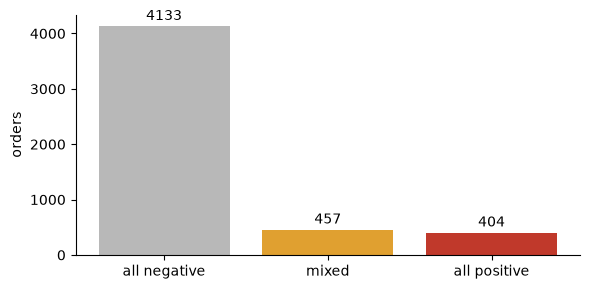

In [5]:
labels["order_id"] = labels["order_line_id"].str.rsplit("-", n=1).str[0]
orders = labels.groupby("order_id")["label"].agg(lines="size", positives="sum")
orders["status"] = np.select(
    [orders["positives"] == 0, orders["positives"] == orders["lines"]],
    ["all negative", "all positive"],
    "mixed",
)
print(
    f"{len(orders):,} orders; lines per order: {orders['lines'].value_counts().sort_index().to_dict()}"
)
print(orders["status"].value_counts().to_string())
fig, ax = plt.subplots(figsize=(6, 3))
counts = orders["status"].value_counts().reindex(["all negative", "mixed", "all positive"])
bars = ax.bar(counts.index, counts.values, color=["#b8b8b8", "#e0a030", "#c0392b"])
ax.bar_label(bars, padding=2)
ax.set_ylabel("orders")
plt.tight_layout()
plt.show()

457 orders have **mixed** labels across their lines: the label is attached at line level, not order level. So the train/test split should group by order
(same order, same side); otherwise lines of the same order, with the same delivery date, land on both sides and make the evaluation score optimistic.

## Positive rate by delivery date

All 7,343 rows were delivered in January 2026 (29 days with orders), so we look at it per day.

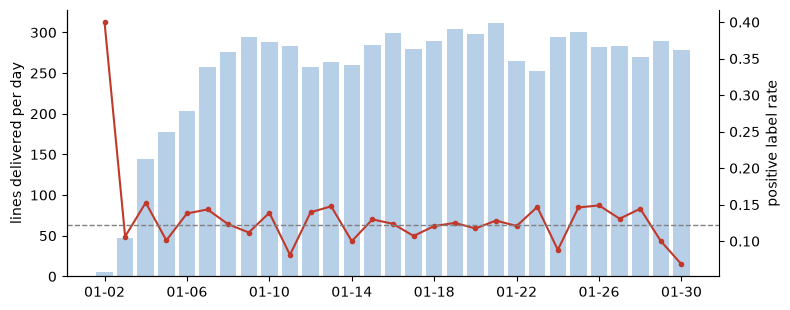

,lines,rate
delivered_at,,
2026-01-02,5,0.400000
2026-01-03,47,0.106383
2026-01-04,144,0.152778


In [6]:
daily = labels.groupby(labels["delivered_at"].dt.date)["label"].agg(lines="size", rate="mean")
fig, ax1 = plt.subplots(figsize=(8, 3.2))
ax1.bar(range(len(daily)), daily["lines"], color="#b8cfe8")
ax1.set_ylabel("lines delivered per day")
ax1.set_xticks(range(0, len(daily), 4), [str(d)[5:] for d in daily.index[::4]])
ax2 = ax1.twinx()
ax2.plot(range(len(daily)), daily["rate"], color="#c0392b", marker="o", ms=3)
ax2.axhline(prevalence, color="gray", ls="--", lw=1)
ax2.set_ylabel("positive label rate")
ax2.spines["right"].set_visible(True)
plt.tight_layout()
plt.show()
daily.sort_values("lines").head(3)

The positive rate hovers around the overall level (dashed line) and is fairly stable on days with about 250–310 rows. The day with the fewest rows (5 rows) has a 40% rate: that is
small-sample noise at the edge of the time range, not a signal. This is simulated generator data, not real numbers from a marketplace.